# 🚀 Practice Day 65

**📅 Date:** 2026-11-06  
📁 Category: Phase 3 · SQL 고급(윈도우함수) (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice window functions in DuckDB — PARTITION BY, a moving average, LAG, and RANK — to analyze multiple game players over time
  (DuckDB 윈도우 함수 연습 — PARTITION BY, 이동평균, LAG, RANK로 여러 플레이어의 시계열 데이터 분석하기)
- Smooth out daily noise to see each player's real trend, catch a slump as it happens, and see how rankings shift day to day
  (일별 노이즈를 걷어내고 플레이어별 실제 추세를 보고, 슬럼프 구간을 포착하고, 순위가 날마다 어떻게 바뀌는지 확인하기)

---
# 📂 Dataset

**Dataset Name:** 5명 플레이어 일별 게임 점수 데이터 / 5-Player Daily Game Scores

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 90 days of daily scores across 5 online game players (NovaStrike, ShadowByte, Lumen_92, Ferrowind, QuartzDrift) — 450 rows total (5 players × 90 days), single table. Each player has their own skill trend and volatility, and Lumen_92 goes through one clear slump partway through the period before recovering. Clean — no missing values or duplicates. The focus is applying window functions per player (PARTITION BY).
(5명의 온라인 게임 플레이어(NovaStrike/ShadowByte/Lumen_92/Ferrowind/QuartzDrift)의 90일간 일별 점수 데이터입니다(단일 테이블, 450행 = 5명×90일). 플레이어마다 고유한 실력 추세와 변동성을 가지며, Lumen_92는 기간 중반에 뚜렷한 슬럼프를 겪었다가 회복합니다. 결측치·중복 없이 깨끗합니다. 플레이어(PARTITION) 단위로 윈도우 함수를 적용하는 데 초점을 둡니다.)

## Dataset Preview

In [18]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate daily scores for 5 online game players over 90 days ---
players = ['NovaStrike', 'ShadowByte', 'Lumen_92', 'Ferrowind', 'QuartzDrift']
base_score = {'NovaStrike': 1200, 'ShadowByte': 2100, 'Lumen_92': 1700, 'Ferrowind': 1900, 'QuartzDrift': 1500}
daily_trend = {'NovaStrike': 0.007, 'ShadowByte': 0.0005, 'Lumen_92': 0.0, 'Ferrowind': -0.004, 'QuartzDrift': 0.001}
daily_vol = {'NovaStrike': 0.06, 'ShadowByte': 0.05, 'Lumen_92': 0.07, 'Ferrowind': 0.06, 'QuartzDrift': 0.05}

n_days = 90
dates = pd.date_range('2024-01-01', periods=n_days, freq='D')

rows = []
for p in players:
    for i, d in enumerate(dates):
        trend_mult = (1 + daily_trend[p]) ** i
        noise = rng.normal(1.0, daily_vol[p])
        s = base_score[p] * trend_mult * noise
        # Lumen_92 goes through a ~3-week slump around day 45, then recovers
        if p == 'Lumen_92':
            slump_center = 45
            if abs(i - slump_center) < 12:
                dip = np.exp(-((i - slump_center) ** 2) / (2 * 4.0 ** 2))
                s = s * (1 - 0.5 * dip)
        s = max(200, s)
        rows.append({'date': d, 'player': p, 'daily_score': int(round(s))})

df = pd.DataFrame(rows).sort_values(['player', 'date']).reset_index(drop=True)

df.head(10)


,date,player,daily_score
0,2024-01-01,Ferrowind,1818
1,2024-01-02,Ferrowind,1928
2,2024-01-03,Ferrowind,1874
3,2024-01-04,Ferrowind,2113
4,2024-01-05,Ferrowind,2046
5,2024-01-06,Ferrowind,1905
6,2024-01-07,Ferrowind,1770
7,2024-01-08,Ferrowind,1724
8,2024-01-09,Ferrowind,1972
9,2024-01-10,Ferrowind,1862


## Dataset Information

In [19]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         450 non-null    datetime64[us]
 1   player       450 non-null    str           
 2   daily_score  450 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 10.7 KB

Shape: (450, 3)


,date,player,daily_score
count,450,450,450.000000
unique,NaN,5,NaN
top,NaN,Ferrowind,NaN
freq,NaN,90,NaN
mean,2024-02-14 12:00:00,NaN,1714.495556
min,2024-01-01 00:00:00,NaN,864.000000
25%,2024-01-23 00:00:00,NaN,1525.000000
50%,2024-02-14 12:00:00,NaN,1662.500000
75%,2024-03-08 00:00:00,NaN,1943.750000
max,2024-03-30 00:00:00,NaN,2466.000000


---
# ❓ Business Questions

1. **(Analysis)** What is each player's 7-day moving average daily score, and how does it smooth out the daily noise (and any slumps)?
   (플레이어별 7일 이동평균 점수는 어떻게 되며, 일별 노이즈(및 슬럼프 구간)를 어떻게 완화하는가?)
2. **(Analysis)** What is each player's day-over-day percentage change in score, and which single day saw the biggest swing?
   (플레이어별 전일 대비 점수 증감률은 얼마이며, 가장 큰 변동을 보인 날은 언제인가?)
3. **(Analysis)** On any given day, how do the 5 players rank against each other by score, and does that ranking ever change?
   (특정 날짜 기준으로 5명의 점수 순위는 어떻게 되며, 그 순위가 바뀌는 경우가 있는가?)
4. **(Visualization)** Show how each player's smoothed (moving average) score trend moves over the 90 days.
   (플레이어별 이동평균 점수 추이는 90일간 어떻게 움직이는가?)
5. **(Visualization)** Compare total score across all 5 players over the full period.
   (전체 기간 5명의 총점을 비교하면?)

---
# 🔍 Data Cleaning Check


In [20]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
date           0
player         0
daily_score    0
dtype: int64

Duplicate rows: 0

Dtypes
date           datetime64[us]
player                    str
daily_score             int64
dtype: object

Column names
['date', 'player', 'daily_score']

Text columns — unique counts
player    5
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** What is each player's 7-day moving average daily score, and how does it smooth out the daily noise? (플레이어별 7일 이동평균 점수는? 노이즈를 어떻게 완화하는가?)

**Result:** On the last day (2024-03-30), the 7-day averages are Ferrowind **1,364.86**, Lumen_92 **1,725.29**, NovaStrike **2,175.57**, QuartzDrift **1,654.71**, and ShadowByte **2,185.57**.  
(마지막 날 기준 7일 이동평균은 Ferrowind **1,364.86**, Lumen_92 **1,725.29**, NovaStrike **2,175.57**, QuartzDrift **1,654.71**, ShadowByte **2,185.57**입니다.)

**Insight:** On the last day, the raw score and the average differ by a few dozen points for most players, for example ShadowByte **2,227** vs **2,185.57** and Ferrowind **1,318** vs **1,364.86**. The first-day average equals the raw score because there is no earlier data (Ferrowind **1,818**).  
(마지막 날 원점수와 이동평균은 대부분 수십 점 차이이며, 예를 들어 ShadowByte는 **2,227**과 **2,185.57**, Ferrowind는 **1,318**과 **1,364.86**입니다. 첫날은 이전 데이터가 없어 이동평균이 원점수와 같습니다(Ferrowind **1,818**).)

In [ ]:
# Question 1 (DuckDB, window function): 7-day moving average daily score per player
import duckdb

seven_day_ma = duckdb.sql("""
    SELECT
        date,
        player,
        daily_score,
        AVG(daily_score) OVER (
            PARTITION BY player ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS ma7
    FROM df
    ORDER BY player, date
""").df()

# Last day per player: raw score vs 7-day average
seven_day_ma[seven_day_ma['date'] == seven_day_ma['date'].max()]


,date,player,daily_score,ma7
89,2024-03-30,Ferrowind,1318,1364.857143
179,2024-03-30,Lumen_92,1700,1725.285714
269,2024-03-30,NovaStrike,2292,2175.571429
359,2024-03-30,QuartzDrift,1671,1654.714286
449,2024-03-30,ShadowByte,2227,2185.571429


## Question 2

**Question:** What is each player's day-over-day percentage change in score, and which single day saw the biggest swing? (전일 대비 증감률은? 가장 큰 변동을 보인 날은?)

**Result:** The biggest swing is Lumen_92 on 2024-03-05 at **+28.07%** (score **1,953**). The next largest are Lumen_92 on 2024-03-10 at **-23.70%**, Lumen_92 on 2024-01-10 at **+23.36%**, and Ferrowind on 2024-01-24 at **-22.56%**.  
(가장 큰 변동은 2024-03-05 Lumen_92의 **+28.07%**(점수 **1,953**)입니다. 그다음은 Lumen_92 2024-03-10 **-23.70%**, Lumen_92 2024-01-10 **+23.36%**, Ferrowind 2024-01-24 **-22.56%**입니다.)

**Insight:** Lumen_92 holds three of the top five swings, and the first day of each player is NaN because there is no previous day.  
(상위 5개 변동 중 3개가 Lumen_92이고, 각 플레이어의 첫날은 전일이 없어 NaN입니다.)

In [22]:
# Question 2 (DuckDB, window function): day-over-day % change per player using LAG
day_over_day_pct_change = duckdb.sql("""
    SELECT
        date,
        player,
        daily_score,
        (daily_score - LAG(daily_score) OVER(
            PARTITION BY player ORDER BY date
        )) /  LAG(daily_score) OVER (PARTITION BY player ORDER BY date) * 100 AS pct_change
    FROM df
    ORDER BY ABS(pct_change) DESC
""").df()

day_over_day_pct_change

,date,player,daily_score,pct_change
0,2024-03-05,Lumen_92,1953,28.065574
1,2024-03-10,Lumen_92,1561,-23.704790
2,2024-01-10,Lumen_92,1896,23.357189
3,2024-01-24,Ferrowind,1466,-22.556788
4,2024-03-08,Lumen_92,1919,22.307202
...,...,...,...,...
445,2024-01-01,NovaStrike,1222,NaN
446,2024-01-01,Lumen_92,1855,NaN
447,2024-01-01,QuartzDrift,1489,NaN
448,2024-01-01,ShadowByte,2170,NaN


## Question 3

**Question:** On any given day, how do the 5 players rank against each other by score, and does that ranking ever change? (특정 날짜 기준 5명의 순위는? 순위가 바뀌는가?)

**Result:** On 2024-01-01 the order is ShadowByte **1**, Lumen_92 **2**, Ferrowind **3**, QuartzDrift **4**, NovaStrike **5**. On 2024-03-30 it is NovaStrike **1**, ShadowByte **2**, Lumen_92 **3**, QuartzDrift **4**, Ferrowind **5**.  
(2024-01-01 순위는 ShadowByte **1**, Lumen_92 **2**, Ferrowind **3**, QuartzDrift **4**, NovaStrike **5**이고, 2024-03-30에는 NovaStrike **1**, ShadowByte **2**, Lumen_92 **3**, QuartzDrift **4**, Ferrowind **5**입니다.)

**Insight:** The ranking changes over the period: NovaStrike moves from **5** to **1** and Ferrowind from **3** to **5**.  
(기간 동안 순위가 바뀌며, NovaStrike는 **5위**에서 **1위**로, Ferrowind는 **3위**에서 **5위**로 이동합니다.)

In [23]:
# Question 3 (DuckDB, window function): daily rank of players by score
daily_rank = duckdb.sql("""
    SELECT
        date,
        player,
        daily_score,
        RANK() OVER (
            PARTITION BY date ORDER BY daily_score DESC
        ) AS rank
    FROM df
    ORDER BY date, rank
""").df()

daily_rank

,date,player,daily_score,rank
0,2024-01-01,ShadowByte,2170,1
1,2024-01-01,Lumen_92,1855,2
2,2024-01-01,Ferrowind,1818,3
3,2024-01-01,QuartzDrift,1489,4
4,2024-01-01,NovaStrike,1222,5
...,...,...,...,...
445,2024-03-30,NovaStrike,2292,1
446,2024-03-30,ShadowByte,2227,2
447,2024-03-30,Lumen_92,1700,3
448,2024-03-30,QuartzDrift,1671,4


---
# 📈 Visualization

**Chart 1:** Line chart — 7-day moving average score trend by player (선그래프: 플레이어별 7일 이동평균 점수 추이)

*Interpretation:* ShadowByte stays on top at about **2,000–2,200**, NovaStrike climbs from about **1,200** to about **2,200** and catches ShadowByte by the end, and Ferrowind falls from about **1,900** to about **1,365**. Lumen_92 drops to about **1,000** in mid-February and then recovers to about **1,725**.  
(ShadowByte는 약 **2,000~2,200**으로 계속 1위권이고, NovaStrike는 약 **1,200**에서 약 **2,200**까지 올라 막바지에 ShadowByte를 따라잡으며, Ferrowind는 약 **1,900**에서 약 **1,365**로 내려갑니다. Lumen_92는 2월 중순 약 **1,000**까지 떨어졌다가 약 **1,725**로 회복합니다.)

---

**Chart 2:** Bar chart — total score by player (막대그래프: 플레이어별 총점)

*Interpretation:* ShadowByte has the highest total at **192,094**, well above NovaStrike at **149,770**. QuartzDrift is lowest at **140,772**, and the gap between 2nd and 5th is only **8,998**.  
(ShadowByte가 총점 **192,094**로 가장 높고 NovaStrike **149,770**보다 크게 앞섭니다. QuartzDrift가 **140,772**로 가장 낮으며, 2위와 5위의 차이는 **8,998**에 불과합니다.)

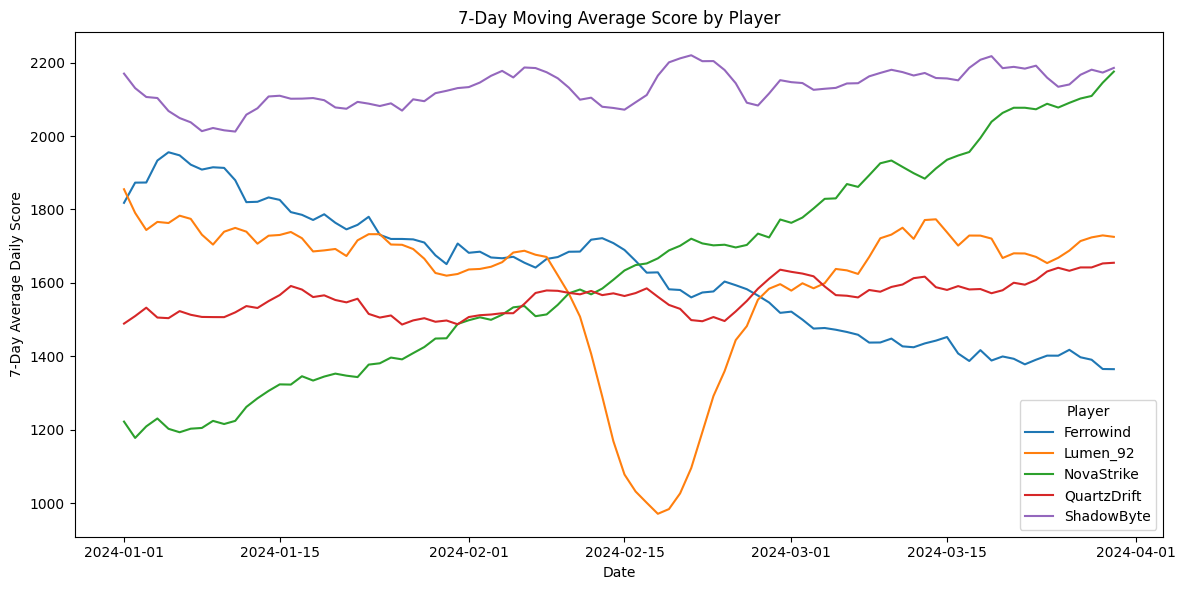

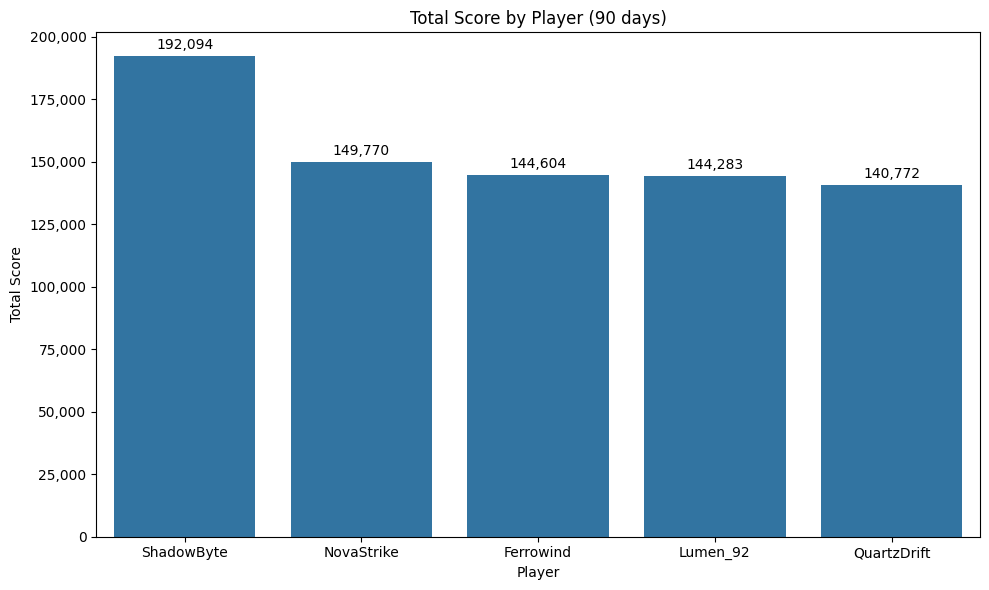

In [24]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Chart 1: 7-day moving average trend per player (reuse the ma7 column from Question 1)
fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=seven_day_ma, x='date', y='ma7', hue='player', ax=ax)
ax.set_title('7-Day Moving Average Score by Player')
ax.set_xlabel('Date')
ax.set_ylabel('7-Day Average Daily Score')
ax.legend(title='Player')
plt.tight_layout()
plt.show()

# Chart 2: total score by player over the full period (bar, sorted high to low)
total_views = df.groupby('player')['daily_score'].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='player', y='daily_score', data=total_views, errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_title('Total Score by Player (90 days)')
ax.set_xlabel('Player')
ax.set_ylabel('Total Score')
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- The 7-day average removes day-to-day noise, so trends such as NovaStrike's rise from about **1,200** to about **2,200** are easy to see.  
  (7일 이동평균이 일별 노이즈를 없애 NovaStrike가 약 **1,200**에서 약 **2,200**으로 오르는 것 같은 추세가 잘 보입니다.)
- Lumen_92 dips to about **1,000** in mid-February and recovers, and it holds three of the top five daily swings.  
  (Lumen_92는 2월 중순 약 **1,000**까지 떨어졌다 회복하고, 일별 변동 상위 5개 중 3개를 차지합니다.)
- ShadowByte has the highest total (**192,094**), but NovaStrike takes rank **1** on the last day.  
  (ShadowByte가 총점 **192,094**로 가장 높지만, 마지막 날 1위는 NovaStrike입니다.)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Judge players by the 7-day average instead of a single day's score, because single-day changes reach about **±28%**.  
   (하루 변동이 최대 약 **±28%**라서 하루 점수 대신 7일 이동평균으로 플레이어를 평가합니다.)
2. Keep an eye on Lumen_92's slump period (mid-February, about **1,000**) to find what caused it.  
   (Lumen_92의 2월 중순 슬럼프(약 **1,000**) 구간 원인을 살펴봅니다.)
3. Watch NovaStrike (rank **5** to **1**) and Ferrowind (rank **3** to **5**) as the biggest movers.  
   (순위가 크게 움직인 NovaStrike(**5위**→**1위**)와 Ferrowind(**3위**→**5위**)를 주시합니다.)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `PARTITION BY` restarts a window function for each player, and `ROWS BETWEEN 6 PRECEDING AND CURRENT ROW` makes a 7-day moving average.  
  (`PARTITION BY`는 플레이어마다 윈도우 함수를 새로 시작하고, `ROWS BETWEEN 6 PRECEDING AND CURRENT ROW`로 7일 이동평균을 만듭니다.)
- `LAG` gives the previous day's score, and `RANK() OVER (PARTITION BY date ...)` ranks players within each day.  
  (`LAG`는 전일 점수를 주고, `RANK() OVER (PARTITION BY date ...)`는 날짜마다 플레이어 순위를 매깁니다.)
- Seaborn has no option to sort bars by size, so I pass the order with `order=` or a sorted table.  
  (seaborn에는 크기순 정렬 옵션이 없어서 `order=`나 정렬된 표로 순서를 넘깁니다.)  

---
# 🧠 Reflection

**What was difficult?**
Getting bars sorted from large to small in seaborn.  
(seaborn에서 막대를 큰 값부터 정렬하는 것.)

**Why?**
`estimator=sum` does the grouping, but seaborn has no automatic ordering.  
(`estimator=sum`이 그룹 합계는 계산하지만 seaborn에는 자동 정렬 기능이 없습니다.)

**How did I solve it?**
I grouped in pandas, sorted descending, and plotted that table so the bars follow the analysis order.  
(pandas로 그룹을 만들고 내림차순 정렬한 표를 그려 막대가 분석 순서를 따르게 했습니다.)

**What would I do differently next time?**
I will pass `order=` from a sorted groupby index when I use `estimator`.  
(`estimator`를 쓸 때는 정렬된 groupby 인덱스를 `order=`로 넘기겠습니다.)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
I can build moving averages, LAG changes, and daily ranks with window functions.  
(윈도우 함수로 이동평균, LAG 증감, 일별 순위를 만들 수 있습니다.)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★☆☆☆☆☆☆☆  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 66 — end-to-end mini pipeline (Round 5/5)  
  (정제부터 집계와 차트까지 한 데이터로 이어 풀기)  